# ICS 3202 — Practical Exercise 3 Extension
## Uniform Cost Search: Nairobi to Kisumu

**Group 7**  
Emmanuel Onyango — 191258  
Rayvon Andeche — 190159  
Austin Maina — 192076  
Atiq Yaasir — 190375

## 1. Search problem formulation

| Part of the problem | Our trailer agent |
|---|---|
| Initial state | Nairobi |
| Goal state | Kisumu |
| States | The ten towns in our original highway graph |
| Actions | Travel along one of the directed road links |
| Step cost | Distance of a road link in kilometres |
| Path cost, **g(n)** | Total distance from Nairobi to the current town |
| Search strategy | **Uniform Cost Search**: expand the frontier path with the lowest **g(n)** |

The graph includes only the selected towns and road links from Practical Exercise 3. The original distances were recorded as *approximate Google Maps road distances on 16 October 2026*. The arrows represent the travel directions included in our model.

UCS uses a **priority queue** ordered by cumulative path cost and that the goal should be accepted when it is **removed from the frontier**, not when it is first discovered.

## 2. Original directed graph and road costs

We record the exact directed links and kilometre values from our group's `design.md`. A dictionary stores each town and its outgoing roads. **No reverse links are added.**

In [ ]:
roads = {
    "Nairobi": {"Naivasha": 92.8, "Narok": 145.0, "Thika": 45.1},
    "Naivasha": {"Nakuru": 70.5},
    "Nakuru": {"Kericho": 107.0},
    "Kericho": {"Kisumu": 84.0},
    "Narok": {"Bomet": 81.0},
    "Bomet": {"Kericho": 76.1},
    "Thika": {"Nyeri": 113.0},
    "Nyeri": {"Nyahururu": 104.0},
    "Nyahururu": {"Nakuru": 63.5},
    "Kisumu": {}
}

start = "Nairobi"
goal = "Kisumu"

number_of_roads = sum(len(links) for links in roads.values())
print(f"Towns: {len(roads)} | Directed roads: {number_of_roads}")
assert len(roads) == 10 and number_of_roads == 11
assert all(km > 0 for links in roads.values() for km in links.values())

Towns: 10 | Directed roads: 11


## 3. Uniform Cost Search (UCS)

UCS keeps possible paths in a **priority queue**. In each step, it:

1. Removes the path with the **smallest total distance**.
2. Expands its current town and considers outgoing roads.
3. Retains a route to a town only if it is **shorter than the route already found**.
4. Stops when **Kisumu is removed** as the cheapest frontier path.

We record the frontier after each expansion to demonstrate the search. When path costs are equal, the program keeps the order in which the paths were inserted.

In [ ]:
import heapq
from itertools import count


def uniform_cost_search(graph, start, goal):
    order = count()
    # Each item is (total cost, insertion order, current town, complete path).
    frontier = [(0.0, next(order), start, [start])]
    best_cost = {start: 0.0}
    expanded = set()
    steps = []

    while frontier:
        cost, _, town, path = heapq.heappop(frontier)

        # Ignore old routes that are longer than a route already discovered.
        if town in expanded or cost > best_cost[town]:
            continue

        expanded.add(town)
        decisions = []

        if town != goal:
            for next_town, road_km in graph[town].items():
                new_cost = round(cost + road_km, 1)

                if next_town not in expanded and new_cost < best_cost.get(next_town, float("inf")):
                    best_cost[next_town] = new_cost
                    heapq.heappush(frontier, (new_cost, next(order), next_town, path + [next_town]))
                    decisions.append(f"Keep {next_town} ({new_cost:.1f} km)")
                else:
                    decisions.append(f"Ignore {next_town} ({new_cost:.1f} km): not shorter")

        # Show current, valid frontier paths in ascending cost order.
        waiting = sorted(
            [entry for entry in frontier
             if entry[2] not in expanded and entry[0] == best_cost[entry[2]]],
            key=lambda item: (item[0], item[1])
        )
        frontier_paths = [(entry[3], entry[0]) for entry in waiting]
        steps.append((town, cost, path, decisions, frontier_paths))

        if town == goal:       # Stop when the goal is REMOVED from the queue.
            return path, cost, steps

    return None, float("inf"), steps

## 4. Step-by-step traversal

Each step below gives the expanded town, its cost **g(n)**, and the remaining paths in the frontier, ordered from the smallest to largest cost. The **ignored** entries are longer ways of reaching towns for which UCS already has a cheaper route.

In [ ]:
optimal_path, optimal_cost, steps = uniform_cost_search(roads, start, goal)

for i, (town, cost, path, decisions, waiting) in enumerate(steps, start=1):
    print(f"STEP {i}: Expand {town} | g(n) = {cost:.1f} km")
    for decision in decisions:
        print("  ", decision)
    print("   Frontier:")
    if waiting:
        for waiting_path, waiting_cost in waiting:
            print(f"     {' -> '.join(waiting_path)} | {waiting_cost:.1f} km")
    else:
        print("     (empty)")
    print()

print("Expansion order:", " -> ".join(row[0] for row in steps))

STEP 1: Expand Nairobi | g(n) = 0.0 km
   Keep Naivasha (92.8 km)
   Keep Narok (145.0 km)
   Keep Thika (45.1 km)
   Frontier:
     Nairobi -> Thika | 45.1 km
     Nairobi -> Naivasha | 92.8 km
     Nairobi -> Narok | 145.0 km

STEP 2: Expand Thika | g(n) = 45.1 km
   Keep Nyeri (158.1 km)
   Frontier:
     Nairobi -> Naivasha | 92.8 km
     Nairobi -> Narok | 145.0 km
     Nairobi -> Thika -> Nyeri | 158.1 km

STEP 3: Expand Naivasha | g(n) = 92.8 km
   Keep Nakuru (163.3 km)
   Frontier:
     Nairobi -> Narok | 145.0 km
     Nairobi -> Thika -> Nyeri | 158.1 km
     Nairobi -> Naivasha -> Nakuru | 163.3 km

STEP 4: Expand Narok | g(n) = 145.0 km
   Keep Bomet (226.0 km)
   Frontier:
     Nairobi -> Thika -> Nyeri | 158.1 km
     Nairobi -> Naivasha -> Nakuru | 163.3 km
     Nairobi -> Narok -> Bomet | 226.0 km

STEP 5: Expand Nyeri | g(n) = 158.1 km
   Keep Nyahururu (262.1 km)
   Frontier:
     Nairobi -> Naivasha -> Nakuru | 163.3 km
     Nairobi -> Narok -> Bomet | 226.0 km
     

## 5. Optimal route and final cost

The path cost is the sum of the road distances between consecutive towns. We calculate it independently from the input graph to check the UCS result.

In [ ]:
if optimal_path is None:
    print("Kisumu is not reachable in this directed graph.")
else:
    print("OPTIMAL PATH:", " -> ".join(optimal_path))
    print("Road distances:")
    total_check = 0.0
    for a, b in zip(optimal_path, optimal_path[1:]):
        km = roads[a][b]
        total_check += km
        print(f"  {a} -> {b}: {km:.1f} km")
    print(f"TOTAL COST: {optimal_cost:.1f} km")

    # Match the result in our original design.md.
    assert optimal_path == ["Nairobi", "Naivasha", "Nakuru", "Kericho", "Kisumu"]
    assert round(optimal_cost, 1) == 354.3
    assert round(total_check, 1) == round(optimal_cost, 1)
    print("Result verified against the original road-distance calculation.")

OPTIMAL PATH: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu
Road distances:
  Nairobi -> Naivasha: 92.8 km
  Naivasha -> Nakuru: 70.5 km
  Nakuru -> Kericho: 107.0 km
  Kericho -> Kisumu: 84.0 km
TOTAL COST: 354.3 km
Result verified against the original road-distance calculation.


## 6. Compare the three original routes

Our earlier `design.md` included these three possible routes. This comparison confirms that UCS returns the least-cost path *within the simplified graph*.

In [ ]:
# These are the same three routes compared in the first part of practical exercise 3.
original_routes = [
    ["Nairobi", "Naivasha", "Nakuru", "Kericho", "Kisumu"],
    ["Nairobi", "Narok", "Bomet", "Kericho", "Kisumu"],
    ["Nairobi", "Thika", "Nyeri", "Nyahururu", "Nakuru", "Kericho", "Kisumu"]
]

for index, route in enumerate(original_routes, start=1):
    cost = round(sum(roads[a][b] for a, b in zip(route, route[1:])), 1)
    print(f"Route {index}: {' -> '.join(route)} | {cost:.1f} km")

Route 1: Nairobi -> Naivasha -> Nakuru -> Kericho -> Kisumu | 354.3 km
Route 2: Nairobi -> Narok -> Bomet -> Kericho -> Kisumu | 386.1 km
Route 3: Nairobi -> Thika -> Nyeri -> Nyahururu -> Nakuru -> Kericho -> Kisumu | 516.6 km


## 7. Directed graph with the optimal path highlighted

This is a visualization of the **same original 11 edges**. The highlighted edges are the optimal path returned by UCS; all other road links remain in the diagram.

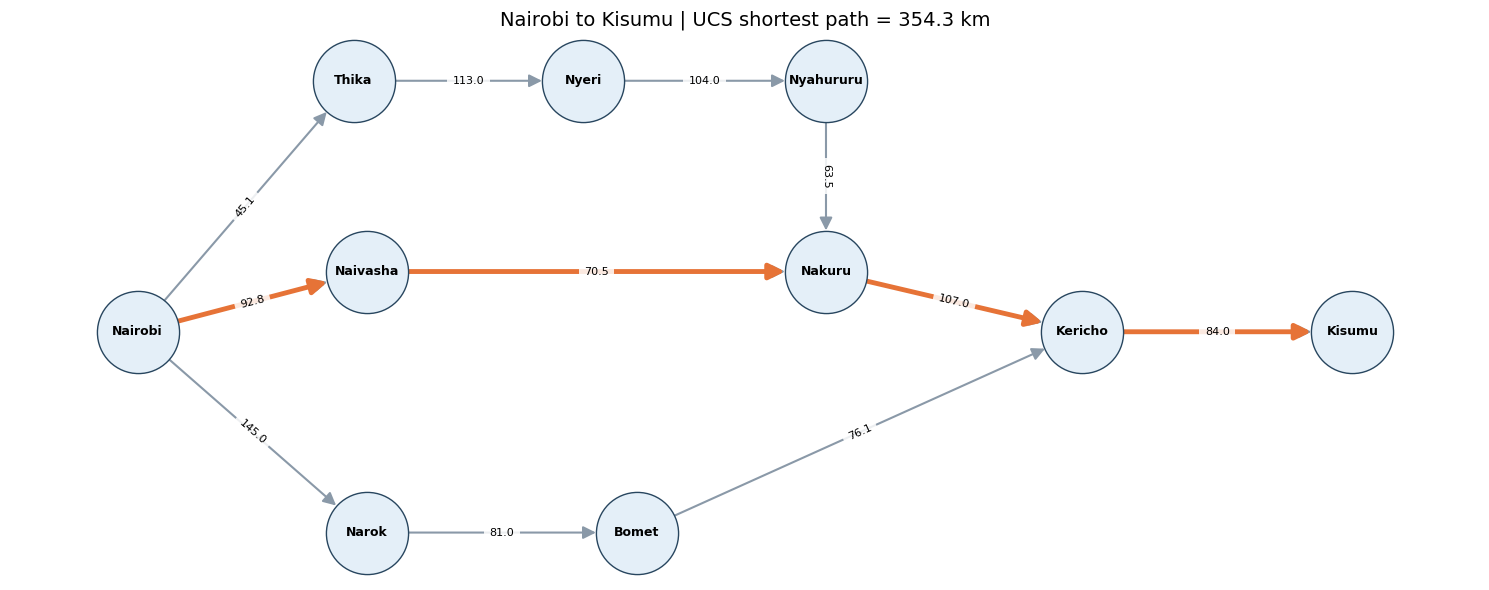

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for town, connections in roads.items():
    G.add_node(town)
    for destination, km in connections.items():
        G.add_edge(town, destination, weight=km)

# Fixed diagram positions
positions = {
    "Nairobi": (0, 0), "Thika": (1.6, 2.5), "Nyeri": (3.3, 2.5),
    "Nyahururu": (5.1, 2.5), "Naivasha": (1.7, 0.6), "Nakuru": (5.1, 0.6),
    "Narok": (1.7, -2), "Bomet": (3.7, -2), "Kericho": (7, 0),
    "Kisumu": (9, 0)
}

chosen_edges = list(zip(optimal_path, optimal_path[1:]))
fig, ax = plt.subplots(figsize=(15, 6))
nx.draw_networkx_nodes(G, positions, node_size=3500, node_color="#E4EFF8", edgecolors="#28465F", ax=ax)
nx.draw_networkx_labels(G, positions, font_size=9, font_weight="bold", ax=ax)
nx.draw_networkx_edges(G, positions, node_size=3500, edge_color="#8A99A8",
                       arrowsize=19, width=1.5, ax=ax)
nx.draw_networkx_edges(G, positions, edgelist=chosen_edges, node_size=3500,
                       edge_color="#E67337", arrowsize=23, width=3.5, ax=ax)
labels = {(a, b): f"{data['weight']:.1f}" for a, b, data in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, positions, edge_labels=labels, font_size=8,
                             bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85}, ax=ax)
ax.set_title(f"Nairobi to Kisumu | UCS shortest path = {optimal_cost:.1f} km", fontsize=14)
ax.axis("off")
plt.tight_layout()
plt.show()

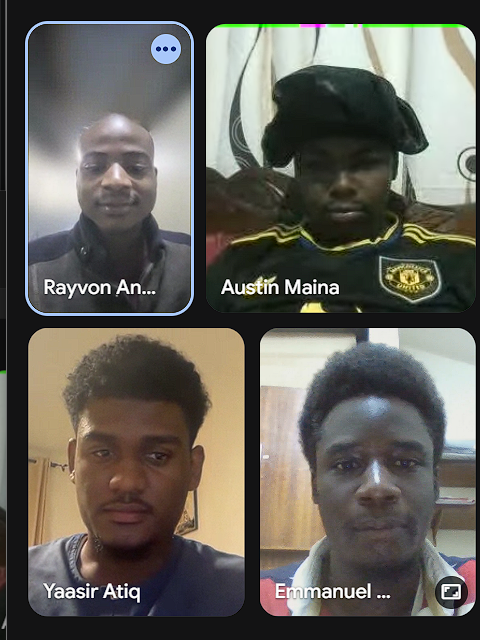

In [1]:
from IPython.display import Image, display

display(Image("/content/Group pic.png"))

## 8. Results

- **Towns expanded:** 10. UCS explores towns in order of **lowest accumulated road distance**, not geographical closeness or number of links.
- **Optimal path:** Nairobi → Naivasha → Nakuru → Kericho → Kisumu.
- **Optimal path cost:** **354.3 km**.
- A second path to **Kericho** through Narok and Bomet would cost **302.1 km** before travelling to Kisumu. UCS retains the shorter **270.3 km** path to Kericho through Naivasha and Nakuru.
- Another path to **Nakuru** through Thika, Nyeri and Nyahururu would cost **325.6 km**; UCS retains the shorter **163.3 km** route via Naivasha.

### Groupphoto


![Group 7 photograph from original design.md](https://github.com/user-attachments/assets/bd7ee0aa-2e58-4d03-a843-08cfbdcd8552)


[Open group photo](https://github.com/user-attachments/assets/bd7ee0aa-2e58-4d03-a843-08cfbdcd8552)

**Repository:** [Galucci4/PS-Agents](https://github.com/Galucci4/PS-Agents)  
**Original graph and distances:** `design.md`  
**Extension notebook:** `UCS_Trailer.ipynb`